1. RF classifier 
2. MS degree centrality percentile 

In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu
from scipy.stats import spearmanr, pearsonr
from tqdm import trange
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)
import shap

DATA_PATH2 = "../../18-finalize/processed-data/"
MS_COLOR   = "#DDAA33"

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titlepad": 25,
    "font.family": "sans-serif",
    "font.sans-serif": "Arial",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

In [2]:
# load the datasets with node centrality information and get nodes 
ms_nodes = pd.read_pickle(f"{DATA_PATH2}20260210-s288c-ANnnotated-Yeast-Interactome.pkl")
print(f"Total proteins in the original MS network: {len(ms_nodes)}")

Total proteins in the original MS network: 3927


In [3]:
# determine which nodes are hubs based on percentile cutoff for degree centrality
cut = 0.10
ms_threshold = ms_nodes["degree_centrality"].quantile(1 - cut)
ms_hubs = ms_nodes[ms_nodes["degree_centrality"] >= ms_threshold]
ms_nothub  = ms_nodes[ms_nodes["degree_centrality"] <  ms_threshold]

print (f"Threshold for defining a hub in MS data is {ms_threshold:.5f}; there are {len(ms_hubs)} hubs and {len(ms_nothub)} non hubs")

Threshold for defining a hub in MS data is 0.01182; there are 393 hubs and 3534 non hubs


In [4]:
# --- Flip sign of cagiada-dG ---
ms_nodes["cagiada-dG"] = -ms_nodes["cagiada-dG"]

In [5]:
# CHAPERONE CATEGORY: three-way classification ===
# 1. Standardize interacting_chaperones lists
def fix_list(val):                     
    if isinstance(val, list):          
        return val
    elif isinstance(val, str):         
        try:
            parsed = ast.literal_eval(val)
            return parsed if isinstance(parsed, list) else []    
        except (ValueError, SyntaxError):
            return []          
    else:
        return []         

ms_nodes["interacting_chaperones"] = (
    ms_nodes["interacting_chaperones"].apply(fix_list)
)


# 2. Identify unique annotated chaperones
chaperone_ids = {                                          #Collects all unique chaperone IDs appearing anywhere in the network's interaction lists.
    chap
    for chaps in ms_nodes["interacting_chaperones"]
    for chap in chaps
}
print(f"Unique annotated chaperones: {len(chaperone_ids)}")


# 3. Create two INDEPENDENT binary attributes

# Is this protein a chaperone?
ms_nodes["is_chaperone"] = (
    ms_nodes["node"].isin(chaperone_ids)
).astype(int)

# Does this protein interact with a chaperone?
ms_nodes["interacts_with_chaperone"] = (
    ms_nodes["interacting_chaperones"].apply(lambda x: len(x) > 0)
).astype(int)


# 4. Create mutually exclusive categories
ms_nodes["chaperone_category"] = np.select(
    [
        ms_nodes["is_chaperone"] == 1,
        ms_nodes["interacts_with_chaperone"] == 1
    ],
    [
        "protein_is_chaperone",
        "protein_interacts_with_chaperone"
    ],
    default="protein_is_neither_chaperone_nor_interacts"
)


# 5. Retain the neither-category indicator
ms_nodes["neither_chaperone_nor_interacts"] = (
    ms_nodes["chaperone_category"]
    == "protein_is_neither_chaperone_nor_interacts"
).astype(int)


# 6. Verify classifications
print("\nChaperone category counts:")
print(ms_nodes["chaperone_category"].value_counts())

print("\nProteins with at least one chaperone interaction:")
print(ms_nodes["interacts_with_chaperone"].sum())

print("\nChaperones that also interact with chaperones:")
print(
    (
        (ms_nodes["is_chaperone"] == 1)
        & (ms_nodes["interacts_with_chaperone"] == 1)
    ).sum()
)

Unique annotated chaperones: 66

Chaperone category counts:
chaperone_category
protein_is_neither_chaperone_nor_interacts    3349
protein_interacts_with_chaperone               512
protein_is_chaperone                            66
Name: count, dtype: int64

Proteins with at least one chaperone interaction:
566

Chaperones that also interact with chaperones:
54


In [6]:
# Track how many proteins remain at each filtering step
summary_rows = []

def record_stage(df, stage, previous_count):
    summary_rows.append({
        "stage": stage,
        "total_remaining": len(df),
        "removed_at_step": previous_count - len(df),
        "hubs": int((df["degree_centrality"] >= ms_threshold).sum()),
        "non_hubs": int((df["degree_centrality"] < ms_threshold).sum()),
        "missing_degree": int(df["degree_centrality"].isna().sum()),
        "ghosh_dill_nonnull": int(df["Ghosh-Dill-dG"].notna().sum()),
        "cagiada_nonnull": int(df["cagiada-dG"].notna().sum()),
        "rosetta_nonnull": int(df["Rosetta_best_total_score"].notna().sum()),
    })

    for category, count in (
        df["DeepTMHMM_class"].fillna("Missing").value_counts().items()
    ):
        summary_rows[-1][f"class_{category}"] = int(count)

# Start with the complete MS network
filtered_nodes = ms_nodes.copy()
record_stage(filtered_nodes, "Before filtering", len(filtered_nodes))

# Step 1: Keep proteins with pLDDT >= 70
previous_count = len(filtered_nodes)
filtered_nodes = filtered_nodes[
    filtered_nodes["mean_plddt"] >= 70
].copy()
record_stage(filtered_nodes, "After pLDDT >= 70", previous_count)

# Step 2: Remove TM, SP+TM, and BETA proteins sequentially
for category in ["TM", "SP+TM", "BETA"]:
    previous_count = len(filtered_nodes)
    filtered_nodes = filtered_nodes[
        ~filtered_nodes["DeepTMHMM_class"].isin([category])
    ].copy()
    record_stage(
        filtered_nodes,
        f"After removing {category}",
        previous_count,
    )

# Generate filtering summary
filtering_summary = pd.DataFrame(summary_rows).fillna(0)

count_columns = filtering_summary.columns.drop("stage")
filtering_summary[count_columns] = (
    filtering_summary[count_columns].astype(int)
)

display(filtering_summary)


,stage,total_remaining,removed_at_step,hubs,non_hubs,missing_degree,ghosh_dill_nonnull,cagiada_nonnull,rosetta_nonnull,class_GLOB,class_TM,class_SP,class_SP+TM,class_Missing,class_BETA
0,Before filtering,3927,0,393,3534,0,3357,3357,3357,3273,457,84,61,51,1
1,After pLDDT >= 70,2964,963,365,2599,0,2528,2528,2528,2465,383,63,52,0,1
2,After removing TM,2581,383,360,2221,0,2528,2528,2528,2465,0,63,52,0,1
3,After removing SP+TM,2529,52,357,2172,0,2528,2528,2528,2465,0,63,0,0,1
4,After removing BETA,2528,1,357,2171,0,2528,2528,2528,2465,0,63,0,0,0


In [7]:
# Identify hubs and non-hubs in the filtered MS network
# Keep the original MS degree-centrality threshold from Cell 2

filtered_ms_hubs = filtered_nodes[
    filtered_nodes["degree_centrality"] >= ms_threshold
].copy()

filtered_ms_nothub = filtered_nodes[
    filtered_nodes["degree_centrality"] < ms_threshold
].copy()

# Verify that every retained protein has a degree-centrality value
assert filtered_nodes["degree_centrality"].notna().all()

# Print the final classification
print(f"Original MS hub threshold: {ms_threshold:.5f}")
print(f"Filtered MS hubs: {len(filtered_ms_hubs)}")
print(f"Filtered MS non-hubs: {len(filtered_ms_nothub)}")
print(f"Total filtered proteins: {len(filtered_nodes)}")
print(f"Hub percentage: {len(filtered_ms_hubs) / len(filtered_nodes) * 100:.2f}%")


Original MS hub threshold: 0.01182
Filtered MS hubs: 357
Filtered MS non-hubs: 2171
Total filtered proteins: 2528
Hub percentage: 14.12%


In [8]:
# ============================================================
# 1. Create the binary target variable
# ============================================================

filtered_nodes["ms_hubs"] = (
    filtered_nodes["degree_centrality"] >= ms_threshold
).astype(int)

print("Target variable distribution:")
print(filtered_nodes["ms_hubs"].value_counts())

# Verify consistency with Cell 4
assert filtered_nodes["ms_hubs"].sum() == len(filtered_ms_hubs)

Target variable distribution:
ms_hubs
0    2171
1     357
Name: count, dtype: int64


In [9]:
# ============================================================
# 2. Define Random Forest predictor features
# ============================================================

ml_features = [
    "Ghosh-Dill-dG",
    "cagiada-dG",
    "Rosetta_best_total_score",
    "Villen_halflife_min",
    "mean_molecules_per_cell",
    "interacts_with_chaperone",
    "in_complex",
    "essential",
    "meltome-melting-point",
    "N_aa_disordered",
    "disorder_fraction",
    "mean_plddt"
]

X = filtered_nodes[ml_features].copy()
y = filtered_nodes["ms_hubs"].copy()

# ============================================================
# 3. Convert predictor features to numeric values
# ============================================================

missing_indicators = [
    "n.d.", "N.D.", "nd", "ND", "na", "NA",
    "null", "NULL", "missing", "MISSING",
    "-", "n/a", "N/A", ""
]

for col in ml_features:
    X[col] = X[col].replace(missing_indicators, np.nan)
    X[col] = pd.to_numeric(X[col], errors="coerce")


# ============================================================
# 4. Examine missing predictor values
# ============================================================

print("\nMissing values by predictor:")
print(X.isna().sum().sort_values(ascending=False))


# ============================================================
# 5. Preserve original missing-value encoding
# ============================================================

#X_filled = X.fillna(-999)


# ============================================================
# 6. Final verification
# ============================================================

print("\nData preparation complete")
print(f"Total samples: {len(X)}")
print(f"Number of predictors: {X.shape[1]}")
print(f"Hubs: {int(y.sum())}")
print(f"Non-hubs: {int((y == 0).sum())}")


Missing values by predictor:
meltome-melting-point       1190
Villen_halflife_min          654
mean_molecules_per_cell        4
Ghosh-Dill-dG                  0
Rosetta_best_total_score       0
cagiada-dG                     0
in_complex                     0
interacts_with_chaperone       0
essential                      0
N_aa_disordered                0
disorder_fraction              0
mean_plddt                     0
dtype: int64

Data preparation complete
Total samples: 2528
Number of predictors: 12
Hubs: 357
Non-hubs: 2171


In [10]:
# Examine missing data separately for hubs and non-hubs

missingness_summary = pd.DataFrame({
    "Missing (n)": X.isna().sum(),
    "Missing (%)": X.isna().mean() * 100,
    "Non-hubs missing (%)": X.loc[y == 0].isna().mean() * 100,
    "Hubs missing (%)": X.loc[y == 1].isna().mean() * 100
})

# Display only predictors with missing values
missingness_summary = missingness_summary[
    missingness_summary["Missing (n)"] > 0
]

display(missingness_summary.round(2))


,Missing (n),Missing (%),Non-hubs missing (%),Hubs missing (%)
Villen_halflife_min,654,25.87,27.96,13.17
mean_molecules_per_cell,4,0.16,0.18,0.00
meltome-melting-point,1190,47.07,50.07,28.85


In [11]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve, confusion_matrix
)

# -------------------------------------------
# Repeated train/test evaluation
# -------------------------------------------

n_models = 50
test_size = 0.2
base_random_state = 42

splitter = StratifiedShuffleSplit(
    n_splits=n_models,
    test_size=test_size,
    random_state=base_random_state
)

results = []
feature_importances_list = []
roc_curves = []

fpr_grid = np.linspace(0, 1, 100)

last_model = None
last_X_test = None
last_y_test = None

# -------------------------------------------
# Train 50 Random Forest models
# -------------------------------------------

for i, (train_idx, test_idx) in enumerate(
    splitter.split(X, y), start=1
):

    # Split the original data (NaNs preserved)
    X_train_raw = X.iloc[train_idx].copy()
    X_test_raw = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Fit median imputation on training data only
    imputer = SimpleImputer(strategy="median")

    X_train = pd.DataFrame(
        imputer.fit_transform(X_train_raw),
        columns=X.columns,
        index=X_train_raw.index
    )

    X_test = pd.DataFrame(
        imputer.transform(X_test_raw),
        columns=X.columns,
        index=X_test_raw.index
    )

    # Initialize Random Forest
    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=base_random_state + i
    )

    # Train model
    rf_model.fit(X_train, y_train)

    # Predict test data
    y_pred = rf_model.predict(X_test)
    y_proba = rf_model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    interp_tpr = np.interp(fpr_grid, fpr, tpr)
    interp_tpr[0] = 0.0
    interp_tpr[-1] = 1.0

    roc_curves.append(interp_tpr)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Store metrics
    results.append({
        "model_num": i,
        "balanced_accuracy": bal_acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

    # Store feature importance
    feature_importances_list.append(
        rf_model.feature_importances_
    )

    # Retain last model for subsequent analysis
    last_model = rf_model
    last_X_test = X_test.copy()
    last_y_test = y_test.copy()

# -------------------------------------------
# Summarize results
# -------------------------------------------

results_df = pd.DataFrame(results)

print("50-model evaluation complete")
print(results_df.describe())

50-model evaluation complete
       model_num  balanced_accuracy  precision     recall         f1  \
count   50.00000          50.000000  50.000000  50.000000  50.000000   
mean    25.50000           0.788739   0.560814   0.662535   0.606286   
std     14.57738           0.028745   0.037383   0.059208   0.039422   
min      1.00000           0.696762   0.481928   0.464789   0.488889   
25%     13.25000           0.770062   0.530987   0.633803   0.581506   
50%     25.50000           0.793557   0.557551   0.661972   0.609181   
75%     37.75000           0.811381   0.586781   0.704225   0.637950   
max     50.00000           0.835600   0.657534   0.774648   0.666667   

         roc_auc          tn         fp         fn         tp  
count  50.000000   50.000000  50.000000  50.000000  50.000000  
mean    0.888793  398.000000  37.000000  23.960000  47.040000  
std     0.021561    5.225526   5.225526   4.203788   4.203788  
min     0.826842  386.000000  25.000000  16.000000  33.000000  
25

In [12]:
metrics_to_summarize = ["balanced_accuracy", "precision", "recall", "f1", "roc_auc"]

print("\nModel Performance Across 50 Runs:")
for metric in metrics_to_summarize:
    mean_val = results_df[metric].mean()
    std_val = results_df[metric].std()
    print(f"{metric}: {mean_val:.3f} ± {std_val:.3f}")


Model Performance Across 50 Runs:
balanced_accuracy: 0.789 ± 0.029
precision: 0.561 ± 0.037
recall: 0.663 ± 0.059
f1: 0.606 ± 0.039
roc_auc: 0.889 ± 0.022


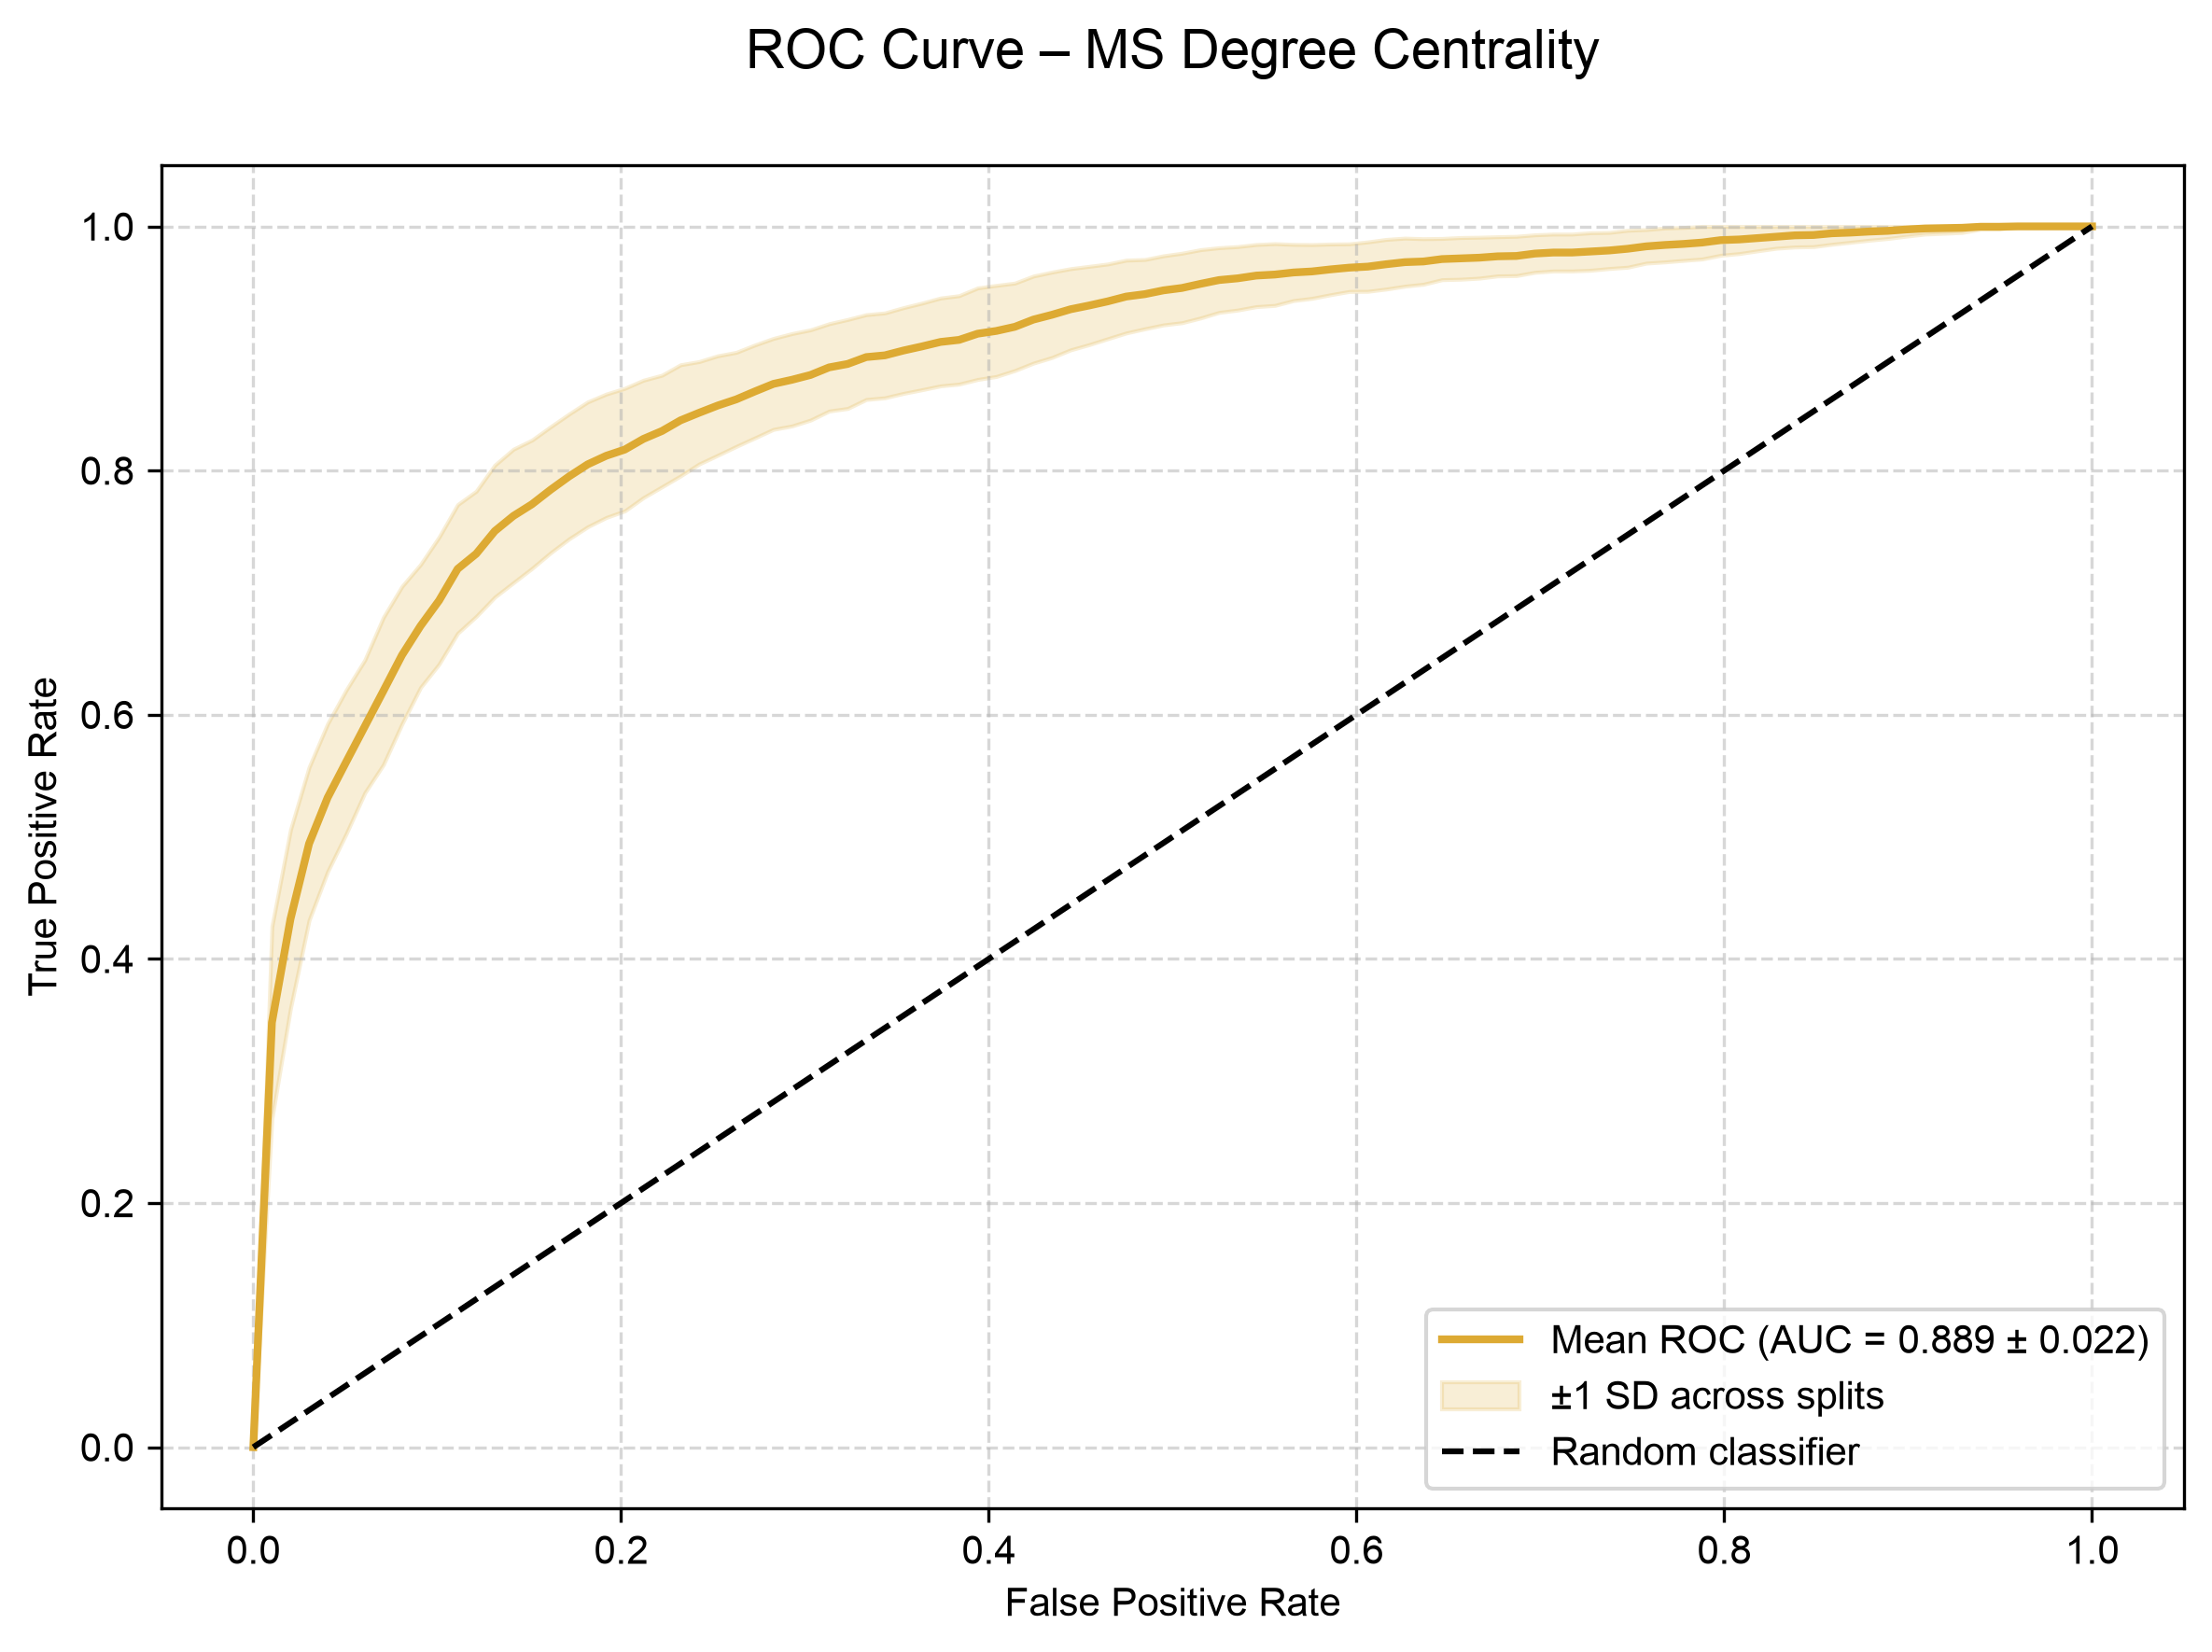

Mean ROC-AUC: 0.889 ± 0.022


In [13]:

# ============================================================
# Calculate mean ROC curve across 50 models
# ============================================================

roc_array = np.array(roc_curves)

mean_tpr = roc_array.mean(axis=0)
std_tpr = roc_array.std(axis=0, ddof=1)

mean_auc = results_df["roc_auc"].mean()
std_auc = results_df["roc_auc"].std()


# ============================================================
# Export ROC curve data
# ============================================================

roc_export_df = pd.DataFrame({
    "False_Positive_Rate": fpr_grid,
    "Mean_True_Positive_Rate": mean_tpr,
    "SD_True_Positive_Rate": std_tpr
})

roc_export_df.to_csv(
    "roc_MS_degree_50models.csv",
    index=False
)


# ============================================================
# Plot mean ROC curve
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_grid,
    mean_tpr,
    color=MS_COLOR,
    linewidth=2,
    label=f"Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})"
)

# Variability across 50 train/test splits
plt.fill_between(
    fpr_grid,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color=MS_COLOR,
    alpha=0.2,
    label="±1 SD across splits"
)

# Random classifier reference
plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – MS Degree Centrality")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Mean ROC-AUC: {mean_auc:.3f} ± {std_auc:.3f}")


In [14]:

# ============================================================
# 1. Collect Gini feature importance from all 50 models
# ============================================================

feature_importances_array = np.array(feature_importances_list)


# ============================================================
# 2. Calculate mean and SD across 50 models
# ============================================================

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Gini_Importance": feature_importances_array.mean(axis=0),
    "SD_Gini_Importance": feature_importances_array.std(axis=0, ddof=1)
}).sort_values(
    by="Mean_Gini_Importance",
    ascending=False
)


# ============================================================
# 3. Display results
# ============================================================

print("\nMean Gini Feature Importances Across 50 Runs:")
print(importance_df.to_string(index=False))



Mean Gini Feature Importances Across 50 Runs:
                 Feature  Mean_Gini_Importance  SD_Gini_Importance
     Villen_halflife_min              0.205361            0.009148
 mean_molecules_per_cell              0.184313            0.009382
   meltome-melting-point              0.116612            0.007975
Rosetta_best_total_score              0.088762            0.005653
              cagiada-dG              0.081714            0.006049
              mean_plddt              0.078380            0.003695
           Ghosh-Dill-dG              0.073445            0.004302
       disorder_fraction              0.054292            0.003630
         N_aa_disordered              0.049026            0.002872
               essential              0.026306            0.003432
interacts_with_chaperone              0.021329            0.003207
              in_complex              0.020458            0.002442


In [15]:

# ============================================================
# SHAP ANALYSIS ACROSS ALL 50 RANDOM FOREST MODELS
# MS degree centrality
# ============================================================

from sklearn.impute import SimpleImputer

# Display names for figures
rename_map = {
    "Ghosh-Dill-dG": "Ghosh & Dill 2010 ΔG(L, T)",
    "cagiada-dG": "Cagiada et al. 2025 ΔG",
    "Rosetta_best_total_score": "Rosetta total score (REU)",
    "Villen_halflife_min": "Protein half-life (min)",
    "mean_molecules_per_cell": "Molecular abundance",
    "interacts_with_chaperone": "Chaperone interaction",
    "in_complex": "In complex",
    "essential": "Essential",
    "meltome-melting-point": "Melting point (°C)",
    "N_aa_disordered": r"$N_{\mathrm{disordered}}$",
    "disorder_fraction": "Disorder fraction",
    "mean_plddt": "Mean pLDDT"
}

# Reproduce the same train/test splits used in Cell 6
splitter_shap = StratifiedShuffleSplit(
    n_splits=n_models,
    test_size=test_size,
    random_state=base_random_state
)

# Storage for SHAP results
mean_abs_shap_list = []
all_shap_values = []
all_X_test = []

print("Computing SHAP across all 50 models...")

for i, (train_idx, test_idx) in enumerate(
    splitter_shap.split(X, y), start=1
):

    # ----------------------------------------
    # 1. Split original data
    # ----------------------------------------

    X_train_raw = X.iloc[train_idx].copy()
    X_test_raw = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx]

    # ----------------------------------------
    # 2. Impute missing values using training data
    # ----------------------------------------

    imputer = SimpleImputer(strategy="median")

    X_train = pd.DataFrame(
        imputer.fit_transform(X_train_raw),
        columns=X.columns,
        index=X_train_raw.index
    )

    X_test = pd.DataFrame(
        imputer.transform(X_test_raw),
        columns=X.columns,
        index=X_test_raw.index
    )

    # ----------------------------------------
    # 3. Recreate the Random Forest model
    # ----------------------------------------

    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        class_weight="balanced",
        random_state=base_random_state + i
    )

    rf_model.fit(X_train, y_train)

    # ----------------------------------------
    # 4. Calculate SHAP values
    # ----------------------------------------

    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_test)

    # Extract SHAP values for class 1 (hub)
    if isinstance(shap_values, list):
        shap_class_values = shap_values[1]

    elif np.asarray(shap_values).ndim == 3:
        shap_class_values = shap_values[:, :, 1]

    else:
        shap_class_values = shap_values

    shap_class_values = np.asarray(shap_class_values)

    assert shap_class_values.shape == X_test.shape

    # ----------------------------------------
    # 5. Mean absolute SHAP per model
    # ----------------------------------------

    mean_abs_shap = np.abs(shap_class_values).mean(axis=0)

    mean_abs_shap_list.append(mean_abs_shap)

    # Store test-set SHAP values for beeswarm
    all_shap_values.append(shap_class_values)
    all_X_test.append(X_test.copy())

    if i % 10 == 0:
        print(f"Completed {i}/{n_models} models")

print("\nSHAP calculation across 50 models completed.")
print(f"Stored models: {len(mean_abs_shap_list)}")
print(f"Number of features: {len(ml_features)}")

Computing SHAP across all 50 models...
Completed 10/50 models
Completed 20/50 models
Completed 30/50 models
Completed 40/50 models
Completed 50/50 models

SHAP calculation across 50 models completed.
Stored models: 50
Number of features: 12


In [16]:
# ============================================================
# SUMMARIZE MEAN ABSOLUTE SHAP ACROSS 50 MODELS
# ============================================================

# 1. Collect SHAP importance from all 50 models
mean_abs_shap_array = np.array(mean_abs_shap_list)

# 2. Verify dimensions: 50 models × 12 predictors
assert mean_abs_shap_array.shape == (n_models, len(ml_features))

# 3. Calculate mean and standard deviation
shap_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Display_Name": [rename_map.get(f, f) for f in X.columns],
    "Mean_Abs_SHAP": mean_abs_shap_array.mean(axis=0),
    "SD_Abs_SHAP": mean_abs_shap_array.std(axis=0, ddof=1)
}).sort_values(
    by="Mean_Abs_SHAP",
    ascending=False
)

# 4. Display results
print("\nMean Absolute SHAP Across 50 Models:")
print(shap_importance_df.to_string(index=False))

# 5. Export results
"""
shap_importance_df.to_csv(
    "mean_abs_shap_MS_degree_50models.csv",
    index=False
)
"""


Mean Absolute SHAP Across 50 Models:
                 Feature               Display_Name  Mean_Abs_SHAP  SD_Abs_SHAP
     Villen_halflife_min    Protein half-life (min)       0.102682     0.004624
 mean_molecules_per_cell        Molecular abundance       0.086889     0.005624
   meltome-melting-point         Melting point (°C)       0.054381     0.004463
Rosetta_best_total_score  Rosetta total score (REU)       0.039293     0.004331
              cagiada-dG     Cagiada et al. 2025 ΔG       0.038792     0.005149
              mean_plddt                 Mean pLDDT       0.027784     0.002536
           Ghosh-Dill-dG Ghosh & Dill 2010 ΔG(L, T)       0.024935     0.003436
               essential                  Essential       0.023129     0.003610
              in_complex                 In complex       0.022959     0.003606
       disorder_fraction          Disorder fraction       0.022644     0.002851
interacts_with_chaperone      Chaperone interaction       0.019440     0.003223
  

'\nshap_importance_df.to_csv(\n    "mean_abs_shap_MS_degree_50models.csv",\n    index=False\n)\n'

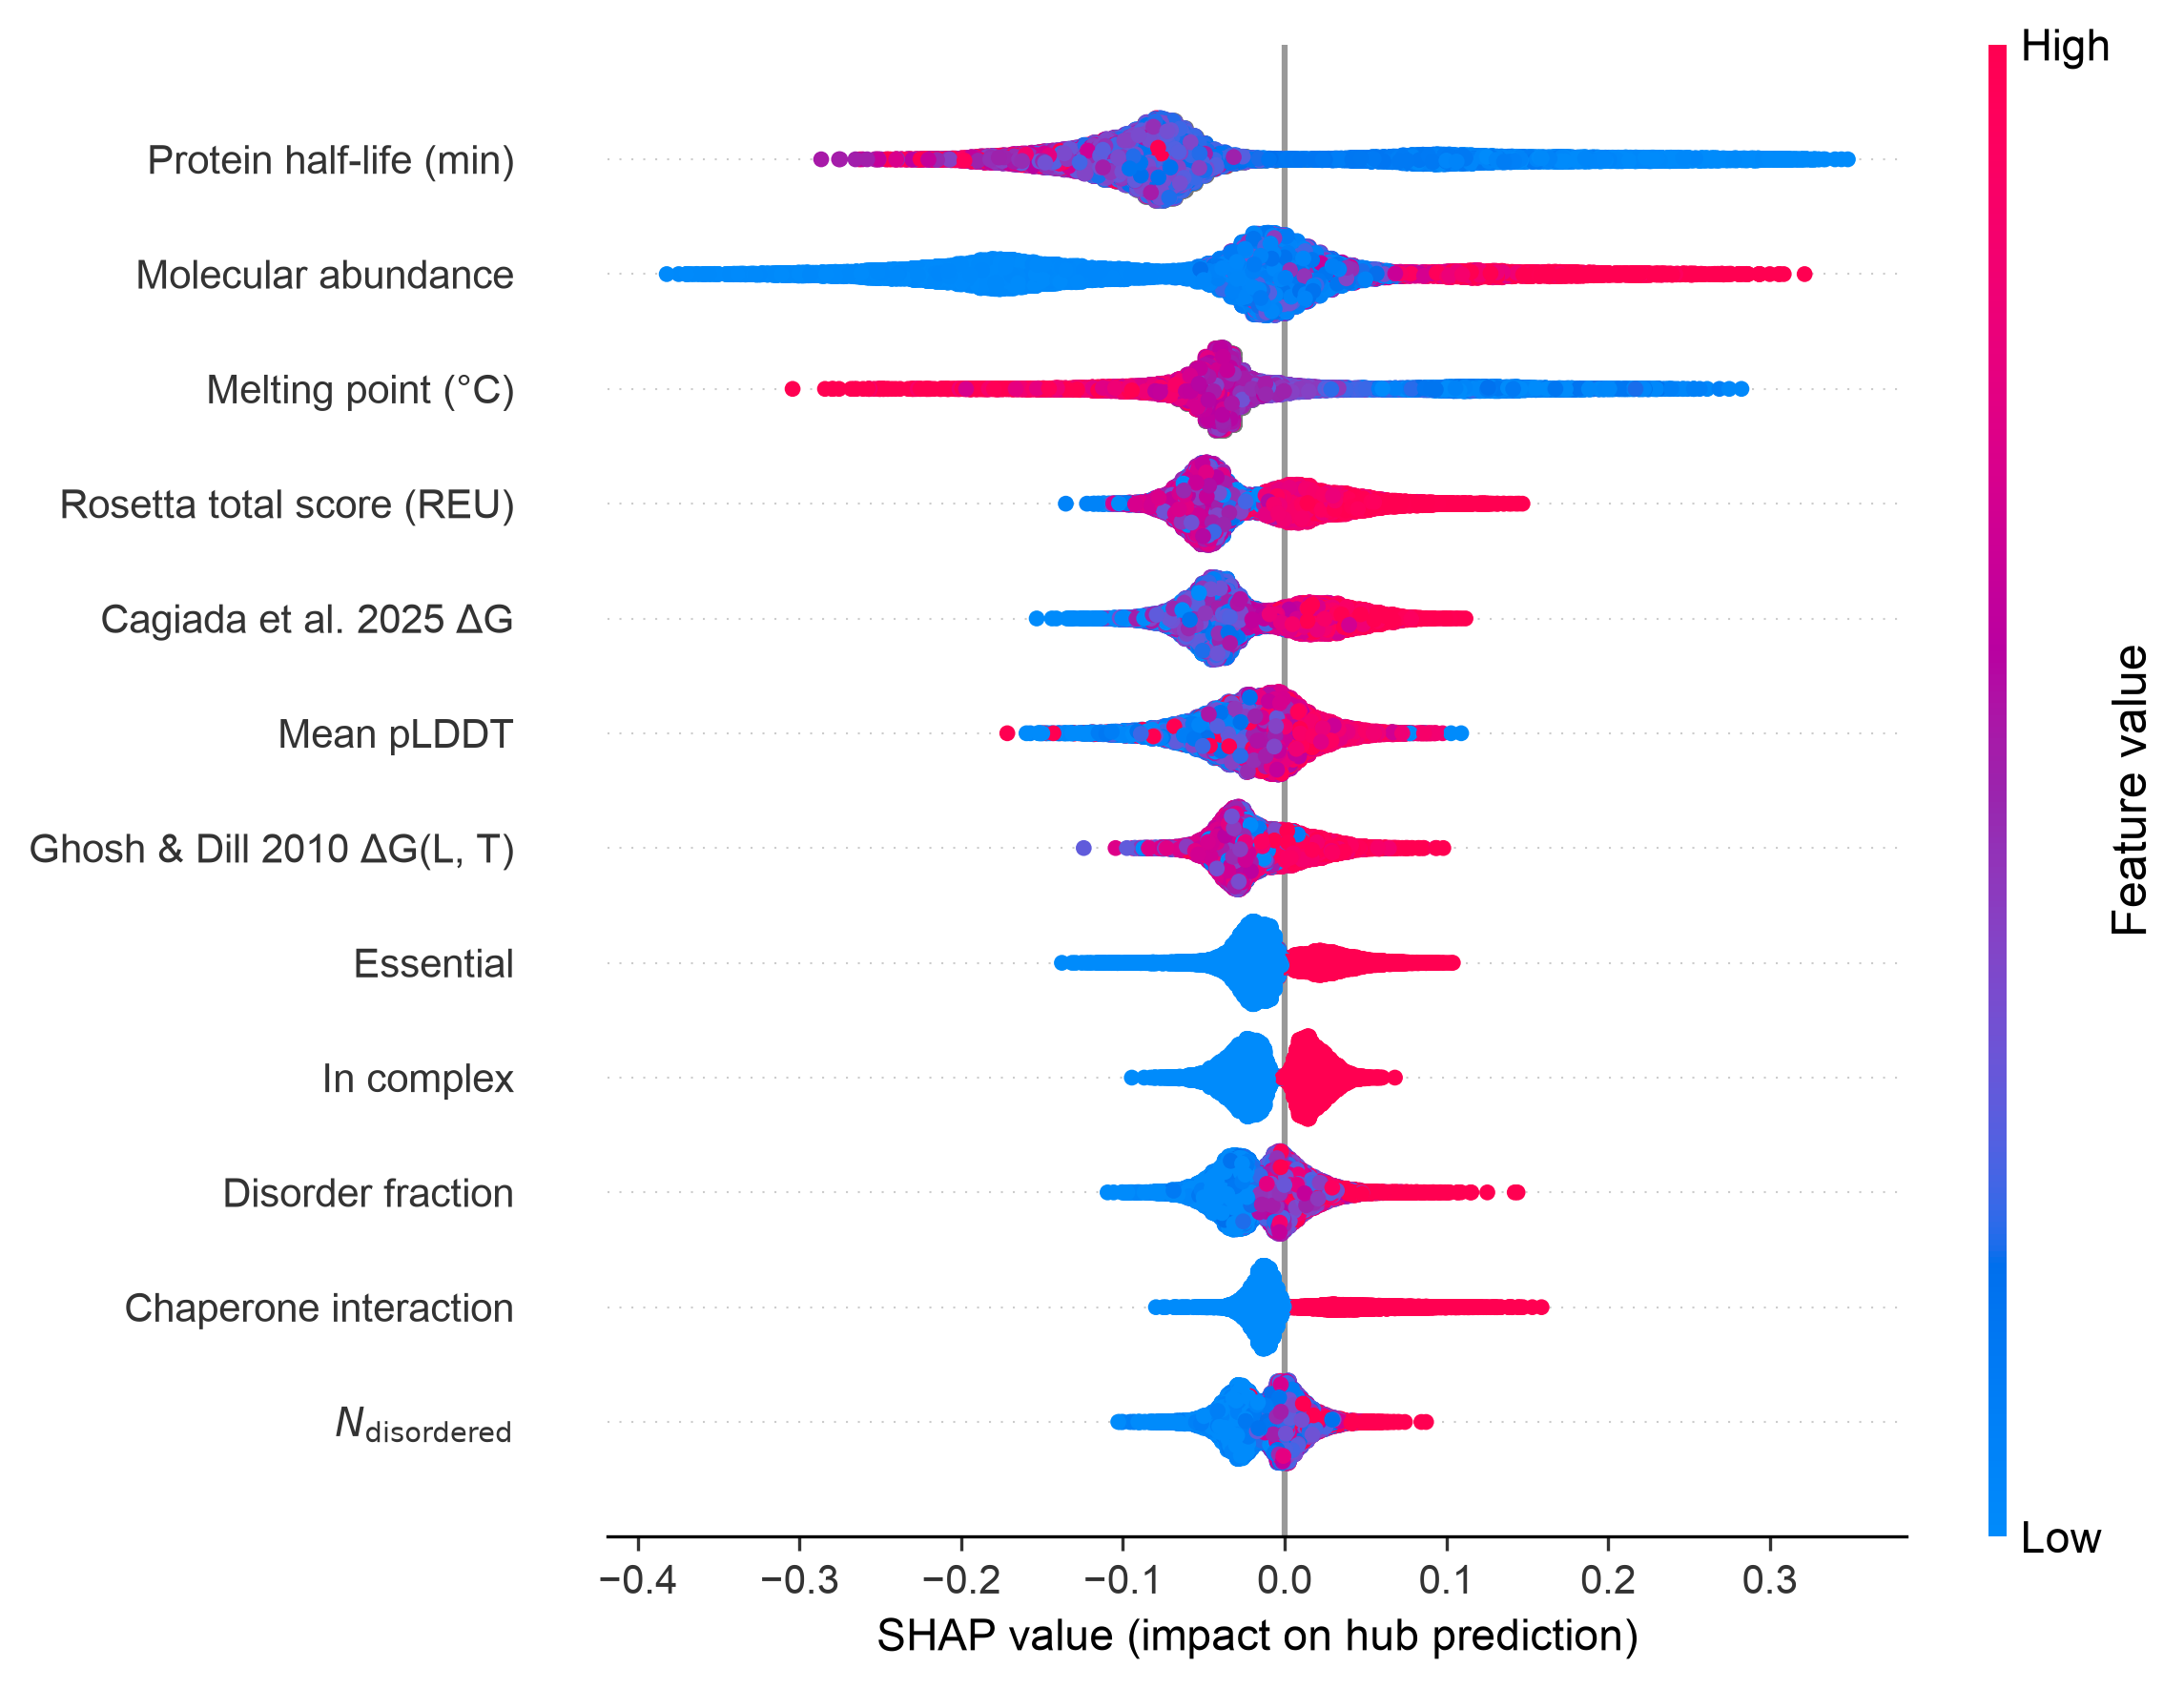

SHAP beeswarm plot generated successfully.
Total test-set predictions: 25300


In [17]:

# ============================================================
# POOLED SHAP BEESWARM ACROSS 50 MODELS
# MS degree centrality
# ============================================================

# 1. Combine test-set SHAP values across all models
pooled_shap_values = np.vstack(all_shap_values)

pooled_X_test = pd.concat(
    all_X_test,
    axis=0
)

# 2. Retrieve original feature values for visualization
# SHAP values remain calculated from imputed model inputs
assert X.index.is_unique

pooled_X_plot = X.loc[pooled_X_test.index].copy()

# 3. Verify matching dimensions
assert pooled_shap_values.shape == pooled_X_plot.shape

# 4. Prepare display names
display_names = [
    rename_map.get(f, f)
    for f in pooled_X_plot.columns
]

# 5. Generate SHAP beeswarm plot
shap.summary_plot(
    pooled_shap_values,
    pooled_X_plot,
    feature_names=display_names,
    plot_type="dot",
    max_display=12,
    plot_size=(8, 6),
    show=False
)

# 6. Format figure
fig = plt.gcf()
ax = plt.gca()

ax.set_xlabel(
    "SHAP value (impact on hub prediction)",
    fontsize=11
)

ax.set_ylabel("")

ax.tick_params(
    axis="both",
    labelsize=10
)

plt.tight_layout()

# 7. Export figure
fig.savefig(
    "SHAP_MS_degree_50models.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

print("SHAP beeswarm plot generated successfully.")
print(f"Total test-set predictions: {len(pooled_X_plot)}")


Percentile: 70 | Threshold: 0.00382 | Hubs:  906 | ROC-AUC: 0.831 ± 0.017
Percentile: 75 | Threshold: 0.00509 | Hubs:  771 | ROC-AUC: 0.842 ± 0.017
Percentile: 80 | Threshold: 0.00688 | Hubs:  646 | ROC-AUC: 0.853 ± 0.020
Percentile: 85 | Threshold: 0.00917 | Hubs:  511 | ROC-AUC: 0.863 ± 0.022
Percentile: 90 | Threshold: 0.01182 | Hubs:  357 | ROC-AUC: 0.889 ± 0.022
Percentile: 95 | Threshold: 0.01605 | Hubs:  193 | ROC-AUC: 0.907 ± 0.025


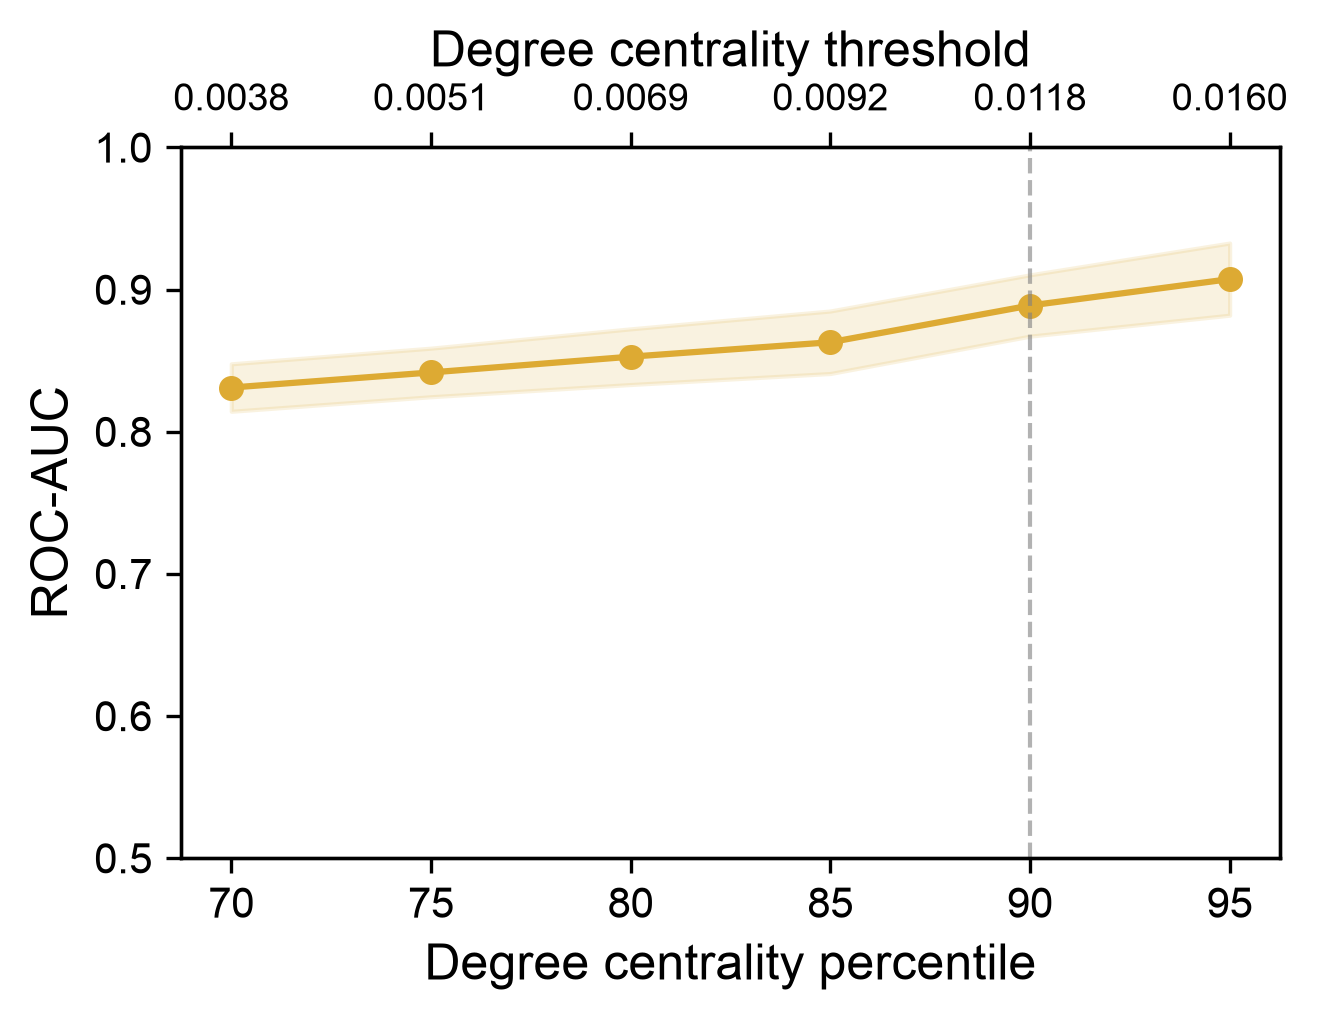

In [18]:

# ============================================================
# SUPPLEMENTARY ANALYSIS
# ROC-AUC ACROSS DEGREE-CENTRALITY PERCENTILE CUTOFFS
# ============================================================

def evaluate_degree_cutoffs(
    original_nodes,
    filtered_nodes,
    X_features,
    percentiles,
    n_repeats=50
):

    thresholds = []
    mean_aucs = []
    sd_aucs = []
    hub_counts = []

    for percentile in percentiles:

        # Calculate cutoff from the ORIGINAL MS network
        threshold = original_nodes["degree_centrality"].quantile(
            percentile / 100
        )

        # Create temporary target labels without modifying data
        y_cutoff = (
            filtered_nodes["degree_centrality"] >= threshold
        ).astype(int)

        # Reproduce the original 80/20 stratified split design
        splitter = StratifiedShuffleSplit(
            n_splits=n_repeats,
            test_size=0.2,
            random_state=42
        )

        aucs = []

        for i, (train_idx, test_idx) in enumerate(
            splitter.split(X_features, y_cutoff), start=1
        ):

            # Training-only median imputation
            imputer = SimpleImputer(strategy="median")

            X_train = imputer.fit_transform(
                X_features.iloc[train_idx]
            )

            X_test = imputer.transform(
                X_features.iloc[test_idx]
            )

            y_train = y_cutoff.iloc[train_idx]
            y_test = y_cutoff.iloc[test_idx]

            # Same hyperparameters as the primary model
            model = RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                min_samples_split=5,
                class_weight="balanced",
                random_state=42 + i
            )

            model.fit(X_train, y_train)

            probabilities = model.predict_proba(X_test)[:, 1]

            aucs.append(
                roc_auc_score(y_test, probabilities)
            )

        thresholds.append(threshold)
        mean_aucs.append(np.mean(aucs))
        sd_aucs.append(np.std(aucs, ddof=1))
        hub_counts.append(int(y_cutoff.sum()))

        print(
            f"Percentile: {percentile:2d} | "
            f"Threshold: {threshold:.5f} | "
            f"Hubs: {int(y_cutoff.sum()):4d} | "
            f"ROC-AUC: {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f}"
        )

    return (
        np.array(thresholds),
        np.array(mean_aucs),
        np.array(sd_aucs),
        np.array(hub_counts)
    )


# ============================================================
# RUN CUTOFF SENSITIVITY ANALYSIS
# ============================================================

cutoff_percentiles = np.array([70, 75, 80, 85, 90, 95])

(
    cutoff_thresholds,
    cutoff_mean_auc,
    cutoff_sd_auc,
    cutoff_hub_counts
) = evaluate_degree_cutoffs(
    original_nodes=ms_nodes,
    filtered_nodes=filtered_nodes,
    X_features=X,
    percentiles=cutoff_percentiles,
    n_repeats=50
)


# ============================================================
# PLOT: ROC-AUC VS DEGREE-CENTRALITY CUTOFF
# ============================================================

fig, ax = plt.subplots(figsize=(3.5, 2.5))

ax.plot(
    cutoff_percentiles,
    cutoff_mean_auc,
    marker="o",
    markersize=5,
    linewidth=1.5,
    color=MS_COLOR
)

# +/- 1 SD across splits
ax.fill_between(
    cutoff_percentiles,
    np.clip(cutoff_mean_auc - cutoff_sd_auc, 0, 1),
    np.clip(cutoff_mean_auc + cutoff_sd_auc, 0, 1),
    color=MS_COLOR,
    alpha=0.15
)

# Highlight original 90th-percentile definition
ax.axvline(
    90,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

ax.set_xlabel("Degree centrality percentile", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)

ax.set_xticks(cutoff_percentiles)
ax.set_ylim(0.5, 1.0)

# Secondary x-axis: actual centrality thresholds
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(cutoff_percentiles)

ax_top.set_xticklabels(
    [f"{value:.4f}" for value in cutoff_thresholds]
)

ax_top.set_xlabel(
    "Degree centrality threshold",
    fontsize=12
)

# Font cleanup
for text in fig.findobj(match=plt.Text):
    text.set_fontfamily("Arial")
    text.set_fontweight("normal")

ax.tick_params(axis="both", labelsize=10)
ax_top.tick_params(axis="x", labelsize=9)

plt.tight_layout()

fig.savefig(
    "Supp-v4.1.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:

# ============================================================
# SUPPLEMENTARY: FULL DEGREE-CENTRALITY CUTOFF SWEEP
# ============================================================

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.impute import SimpleImputer

def full_degree_cutoff_sweep(
    original_nodes,
    filtered_nodes,
    features,
    n_repeats=50,
    min_class_size=25
):

    # All unique raw degree-centrality values
    original_degree = original_nodes["degree_centrality"].dropna().to_numpy()
    unique_cutoffs = np.sort(np.unique(original_degree))

    # Storage (no new DataFrames)
    raw_values = []
    percentile_values = []
    mean_aucs = []
    sd_aucs = []
    hub_counts = []

    # Cache results when two cutoffs produce identical labels
    cache = {}

    assert features.index.equals(filtered_nodes.index)

    for threshold in unique_cutoffs:

        labels = (
            filtered_nodes["degree_centrality"] >= threshold
        ).astype(int)

        n_hubs = int(labels.sum())
        n_nonhubs = len(labels) - n_hubs

        # Exclude cutoffs with very small classes
        if min(n_hubs, n_nonhubs) < min_class_size:
            continue

        # Percentile position in ORIGINAL network
        percentile = 100 * np.mean(original_degree < threshold)

        if n_hubs not in cache:

            splitter = StratifiedShuffleSplit(
                n_splits=n_repeats,
                test_size=0.20,
                random_state=42
            )

            aucs = []

            for i, (train_idx, test_idx) in enumerate(
                splitter.split(features, labels), start=1
            ):

                imputer = SimpleImputer(strategy="median")

                X_train = imputer.fit_transform(
                    features.iloc[train_idx]
                )
                X_test = imputer.transform(
                    features.iloc[test_idx]
                )

                y_train = labels.iloc[train_idx]
                y_test = labels.iloc[test_idx]

                model = RandomForestClassifier(
                    n_estimators=200,
                    max_depth=10,
                    min_samples_split=5,
                    class_weight="balanced",
                    random_state=42 + i
                )

                model.fit(X_train, y_train)

                probabilities = model.predict_proba(X_test)[:, 1]

                aucs.append(
                    roc_auc_score(y_test, probabilities)
                )

            cache[n_hubs] = (
                np.mean(aucs),
                np.std(aucs, ddof=1)
            )

        mean_auc, sd_auc = cache[n_hubs]

        raw_values.append(threshold)
        percentile_values.append(percentile)
        mean_aucs.append(mean_auc)
        sd_aucs.append(sd_auc)
        hub_counts.append(n_hubs)

    return tuple(
        np.array(values)
        for values in (
            raw_values,
            percentile_values,
            mean_aucs,
            sd_aucs,
            hub_counts
        )
    )


# ============================================================
# RUN INDEPENDENT SUPPLEMENTARY ANALYSIS
# ============================================================

(
    sweep_raw,
    sweep_percentile,
    sweep_auc,
    sweep_sd,
    sweep_hubs
) = full_degree_cutoff_sweep(
    original_nodes=ms_nodes,
    filtered_nodes=filtered_nodes,
    features=X,
    n_repeats=50,
    min_class_size=25
)

print(f"Number of evaluated cutoffs: {len(sweep_raw)}")
print(f"Original 90th-percentile threshold: {ms_threshold:.5f}")
print(f"Original model ROC-AUC: {results_df['roc_auc'].mean():.3f}")


Number of evaluated cutoffs: 101
Original 90th-percentile threshold: 0.01182
Original model ROC-AUC: 0.889


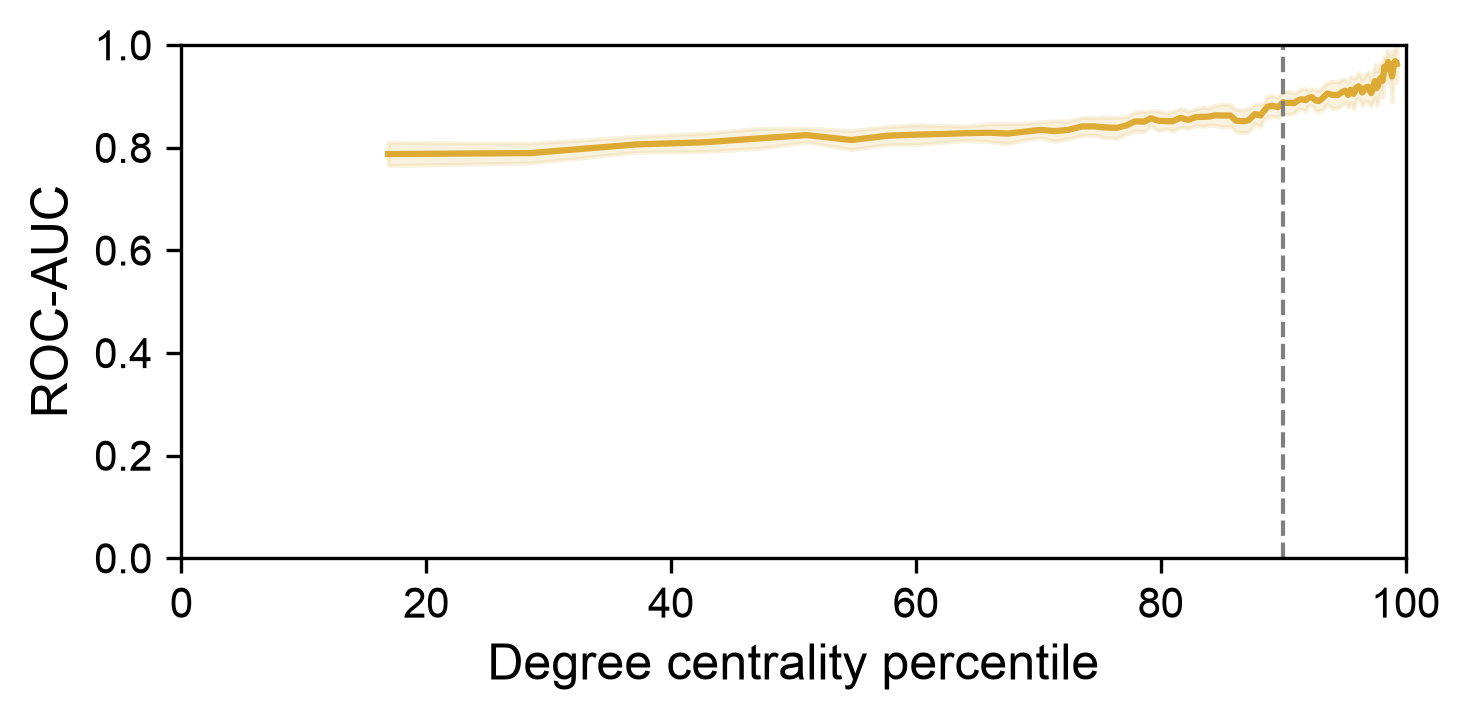

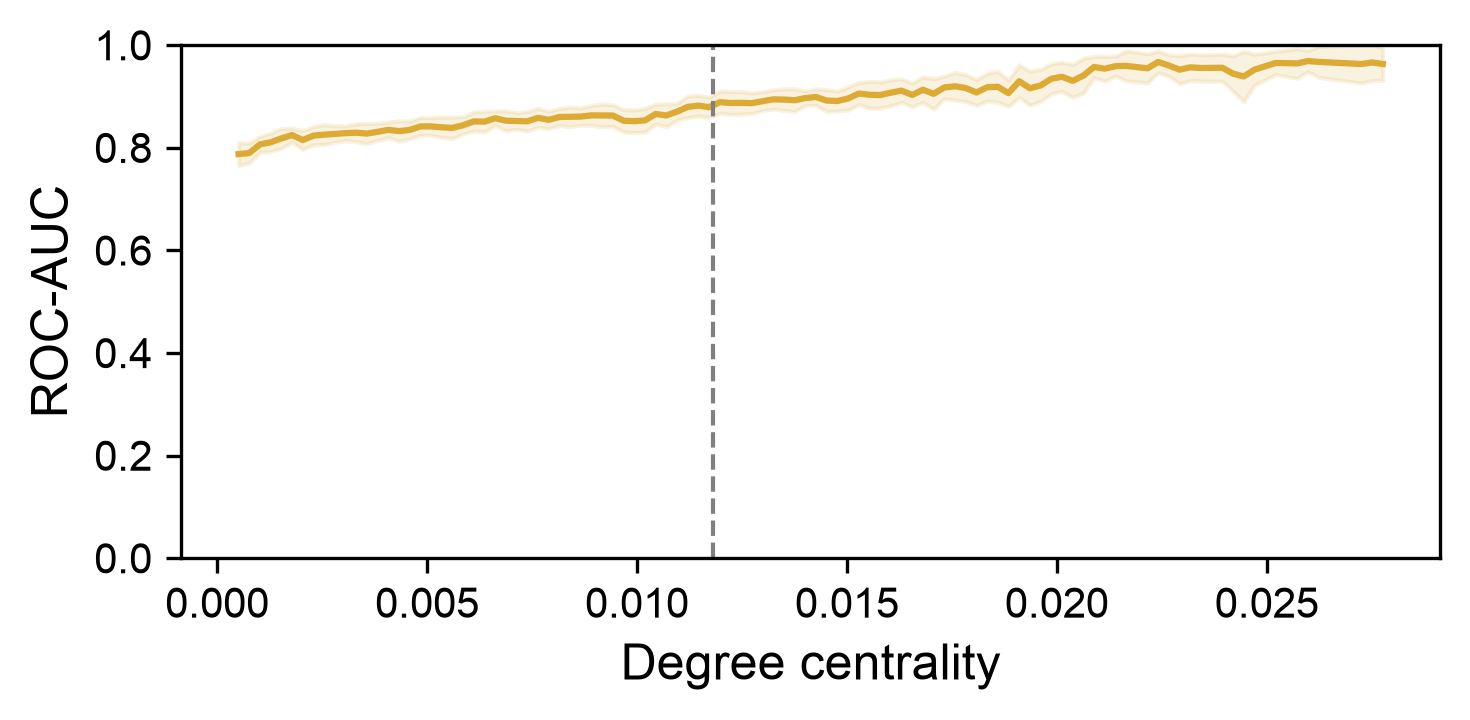

In [20]:
# ============================================================
# FIGURE A: ROC-AUC VS DEGREE-CENTRALITY PERCENTILE
# ============================================================

fig, ax = plt.subplots(figsize=(5, 2.5))

ax.plot(
    sweep_percentile,
    sweep_auc,
    color=MS_COLOR,
    linewidth=1.5
)

ax.fill_between(
    sweep_percentile,
    np.clip(sweep_auc - sweep_sd, 0, 1),
    np.clip(sweep_auc + sweep_sd, 0, 1),
    color=MS_COLOR,
    alpha=0.15
)

ax.axvline(90, color="gray", linestyle="--", linewidth=1)

ax.set_xlabel("Degree centrality percentile", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_xlim(0, 100)
ax.set_ylim(0, 1)

ax.tick_params(labelsize=10)
plt.tight_layout()

"""
fig.savefig(
    "ROC_AUC_vs_MS_degree_percentile.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()


# ============================================================
# FIGURE B: ROC-AUC VS RAW DEGREE CENTRALITY
# ============================================================

fig, ax = plt.subplots(figsize=(5, 2.5))

ax.plot(
    sweep_raw,
    sweep_auc,
    color=MS_COLOR,
    linewidth=1.5
)

ax.fill_between(
    sweep_raw,
    np.clip(sweep_auc - sweep_sd, 0, 1),
    np.clip(sweep_auc + sweep_sd, 0, 1),
    color=MS_COLOR,
    alpha=0.15
)

ax.axvline(
    ms_threshold,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Degree centrality", fontsize=12)
ax.set_ylabel("ROC-AUC", fontsize=12)
ax.set_ylim(0, 1)

ax.tick_params(labelsize=10)
plt.tight_layout()

"""
fig.savefig(
    "ROC_AUC_vs_MS_raw_degree.svg",
    format="svg",
    dpi=300,
    bbox_inches="tight"
)
"""

plt.show()
